In [1]:
!pip -q install nltk scikit-learn textblob wordcloud matplotlib tensorflow

In [2]:
# Q1. Write a unique paragraph (5-6 sentences) about your favorite topic.
# 1. Convert text to lowercase and remove punctuation using re.
# 2. Tokenize the text into words and sentences.
# 3. Compare split() and word_tokenize().
# 4. Remove stopwords using NLTK.
# 5. Display word frequency distribution excluding stopwords.

import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

text = """Technology has changed the way we live and communicate.
Artificial intelligence helps people complete difficult tasks quickly.
Students use technology to learn new skills and explore creative ideas.
Modern smartphones make communication easier and faster.
Technology also improves healthcare, education, and transportation.
I believe technology will create many exciting opportunities in the future."""

clean_text = re.sub(r'[^\w\s]', '', text.lower())
sentences = sent_tokenize(text)
words = word_tokenize(clean_text)
split_words = clean_text.split()
stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]
frequency = FreqDist(filtered_words)

print('Clean Text:', clean_text)
print('\nSentences:', sentences)
print('\nWord Tokenization:', words)
print('\nSplit Tokenization:', split_words)
print('\nNLTK Tokens:', len(words))
print('Split Tokens:', len(split_words))
print('\nWithout Stopwords:', filtered_words)
print('\nWord Frequency:', frequency.most_common())

Clean Text: technology has changed the way we live and communicate
artificial intelligence helps people complete difficult tasks quickly
students use technology to learn new skills and explore creative ideas
modern smartphones make communication easier and faster
technology also improves healthcare education and transportation
i believe technology will create many exciting opportunities in the future

Sentences: ['Technology has changed the way we live and communicate.', 'Artificial intelligence helps people complete difficult tasks quickly.', 'Students use technology to learn new skills and explore creative ideas.', 'Modern smartphones make communication easier and faster.', 'Technology also improves healthcare, education, and transportation.', 'I believe technology will create many exciting opportunities in the future.']

Word Tokenization: ['technology', 'has', 'changed', 'the', 'way', 'we', 'live', 'and', 'communicate', 'artificial', 'intelligence', 'helps', 'people', 'complete', '

In [3]:
# Q2. Using the same paragraph from Q1:
# 1. Extract alphabetic words using re.findall().
# 2. Remove stopwords using NLTK.
# 3. Perform stemming using PorterStemmer.
# 4. Perform lemmatization using WordNetLemmatizer.
# 5. Compare stemming and lemmatization and explain their uses.

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

words = re.findall(r'[a-zA-Z]+', text.lower())
stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
stemmed = [stemmer.stem(word) for word in filtered_words]
lemmatized = [lemmatizer.lemmatize(word) for word in filtered_words]

print('Original Words:', filtered_words)
print('\nStemmed Words:', stemmed)
print('\nLemmatized Words:', lemmatized)
print('\nComparison:')
for original, stem, lemma in zip(filtered_words, stemmed, lemmatized):
    print(original, '->', stem, '->', lemma)
print('\nStemming is faster and useful for search engines.')
print('Lemmatization preserves meaningful words and is useful for NLP tasks.')

Original Words: ['technology', 'changed', 'way', 'live', 'communicate', 'artificial', 'intelligence', 'helps', 'people', 'complete', 'difficult', 'tasks', 'quickly', 'students', 'use', 'technology', 'learn', 'new', 'skills', 'explore', 'creative', 'ideas', 'modern', 'smartphones', 'make', 'communication', 'easier', 'faster', 'technology', 'also', 'improves', 'healthcare', 'education', 'transportation', 'believe', 'technology', 'create', 'many', 'exciting', 'opportunities', 'future']

Stemmed Words: ['technolog', 'chang', 'way', 'live', 'commun', 'artifici', 'intellig', 'help', 'peopl', 'complet', 'difficult', 'task', 'quickli', 'student', 'use', 'technolog', 'learn', 'new', 'skill', 'explor', 'creativ', 'idea', 'modern', 'smartphon', 'make', 'commun', 'easier', 'faster', 'technolog', 'also', 'improv', 'healthcar', 'educ', 'transport', 'believ', 'technolog', 'creat', 'mani', 'excit', 'opportun', 'futur']

Lemmatized Words: ['technology', 'changed', 'way', 'live', 'communicate', 'artific

In [4]:
# Q3. Choose 3 short texts of your own.
# 1. Generate Bag of Words using CountVectorizer.
# 2. Compute TF-IDF scores using TfidfVectorizer.
# 3. Print and interpret the top 3 keywords from each text.

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import numpy as np

texts = [
    'Artificial intelligence improves automation and intelligent decision making.',
    'Machine learning helps computers recognize patterns and predict outcomes.',
    'Cybersecurity protects computer networks and prevents digital attacks.'
]
count_vectorizer = CountVectorizer()
bow = count_vectorizer.fit_transform(texts)
print('Bag of Words Features:', count_vectorizer.get_feature_names_out())
print('\nBag of Words Matrix:\n', bow.toarray())
tfidf_vectorizer = TfidfVectorizer()
tfidf = tfidf_vectorizer.fit_transform(texts)
features = tfidf_vectorizer.get_feature_names_out()
print('\nTF-IDF Matrix:\n', tfidf.toarray())
for i, row in enumerate(tfidf.toarray()):
    top_indices = np.argsort(row)[::-1][:3]
    keywords = [(features[j], round(row[j], 3)) for j in top_indices]
    print(f'\nText {i + 1} Top 3 Keywords:', keywords)
    print('Interpretation: These keywords represent the important terms in this text.')

Bag of Words Features: ['and' 'artificial' 'attacks' 'automation' 'computer' 'computers'
 'cybersecurity' 'decision' 'digital' 'helps' 'improves' 'intelligence'
 'intelligent' 'learning' 'machine' 'making' 'networks' 'outcomes'
 'patterns' 'predict' 'prevents' 'protects' 'recognize']

Bag of Words Matrix:
 [[1 1 0 1 0 0 0 1 0 0 1 1 1 0 0 1 0 0 0 0 0 0 0]
 [1 0 0 0 0 1 0 0 0 1 0 0 0 1 1 0 0 1 1 1 0 0 1]
 [1 0 1 0 1 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 1 1 0]]

TF-IDF Matrix:
 [[0.21786941 0.36888498 0.         0.36888498 0.         0.
  0.         0.36888498 0.         0.         0.36888498 0.36888498
  0.36888498 0.         0.         0.36888498 0.         0.
  0.         0.         0.         0.         0.        ]
 [0.20440549 0.         0.         0.         0.         0.34608857
  0.         0.         0.         0.34608857 0.         0.
  0.         0.34608857 0.34608857 0.         0.         0.34608857
  0.34608857 0.34608857 0.         0.         0.34608857]
 [0.21786941 0.         0.3

In [5]:
# Q4. Write two short texts of 4-6 lines describing different technologies.
# 1. Preprocess and tokenize both texts.
# 2. Calculate Jaccard Similarity using sets.
# 3. Calculate Cosine Similarity using TF-IDF.
# 4. Analyze which similarity metric provides better insights.

import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1 = """Artificial intelligence enables machines to learn from data.
It helps automate complex tasks.
AI improves healthcare and education.
Machine learning is an important part of AI.
AI systems can recognize images and speech."""
text2 = """Blockchain is a secure digital ledger technology.
It stores data across distributed networks.
Blockchain enables transparent transactions.
It is widely used in digital currencies.
Blockchain improves security and data integrity."""

def preprocess(text):
    return re.findall(r'[a-z]+', text.lower())

words1 = set(preprocess(text1))
words2 = set(preprocess(text2))
jaccard = len(words1.intersection(words2)) / len(words1.union(words2))
vectorizer = TfidfVectorizer()
vectors = vectorizer.fit_transform([text1, text2])
cosine = cosine_similarity(vectors[0], vectors[1])[0][0]
print('Text 1 Tokens:', words1)
print('\nText 2 Tokens:', words2)
print('\nJaccard Similarity:', round(jaccard, 4))
print('Cosine Similarity:', round(cosine, 4))
print('\nAnalysis:')
print('Jaccard measures similarity using common unique words.')
print('Cosine uses TF-IDF weights to compare word importance.')
print('Cosine similarity provides better insights into important shared terms.')

Text 1 Tokens: {'healthcare', 'images', 'part', 'can', 'speech', 'machine', 'recognize', 'complex', 'systems', 'learning', 'an', 'to', 'data', 'important', 'learn', 'from', 'automate', 'artificial', 'helps', 'machines', 'enables', 'it', 'education', 'of', 'is', 'ai', 'and', 'intelligence', 'tasks', 'improves'}

Text 2 Tokens: {'transparent', 'across', 'transactions', 'blockchain', 'stores', 'used', 'data', 'secure', 'integrity', 'a', 'technology', 'ledger', 'distributed', 'enables', 'it', 'security', 'currencies', 'is', 'in', 'and', 'networks', 'widely', 'digital', 'improves'}

Jaccard Similarity: 0.125
Cosine Similarity: 0.1403

Analysis:
Jaccard measures similarity using common unique words.
Cosine uses TF-IDF weights to compare word importance.
Cosine similarity provides better insights into important shared terms.



Review: This laptop is excellent and works perfectly.
Polarity: 1.0
Subjectivity: 1.0
Sentiment: Positive

Review: The battery life is amazing and performance is great.
Polarity: 0.7000000000000001
Subjectivity: 0.825
Sentiment: Positive

Review: The product is terrible and very disappointing.
Polarity: -0.89
Subjectivity: 0.955
Sentiment: Negative

Review: The screen quality is poor and the laptop is slow.
Polarity: -0.35000000000000003
Subjectivity: 0.5
Sentiment: Negative

Review: The laptop has a keyboard and a screen.
Polarity: 0.0
Subjectivity: 0.0
Sentiment: Neutral

Review: I love the design and the excellent display.
Polarity: 0.75
Subjectivity: 0.8
Sentiment: Positive


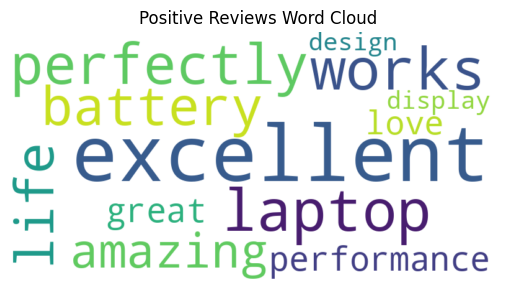

In [6]:
# Q5. Write short reviews for a product or service.
# 1. Find polarity and subjectivity using TextBlob.
# 2. Classify reviews as Positive, Negative, or Neutral.
# 3. Create a word cloud for all positive reviews.

from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    'This laptop is excellent and works perfectly.',
    'The battery life is amazing and performance is great.',
    'The product is terrible and very disappointing.',
    'The screen quality is poor and the laptop is slow.',
    'The laptop has a keyboard and a screen.',
    'I love the design and the excellent display.'
]
positive_reviews = []
for review in reviews:
    analysis = TextBlob(review)
    polarity = analysis.sentiment.polarity
    subjectivity = analysis.sentiment.subjectivity
    if polarity > 0:
        sentiment = 'Positive'
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = 'Negative'
    else:
        sentiment = 'Neutral'
    print('\nReview:', review)
    print('Polarity:', polarity)
    print('Subjectivity:', subjectivity)
    print('Sentiment:', sentiment)
positive_text = ' '.join(positive_reviews)
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(positive_text)
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Positive Reviews Word Cloud')
plt.show()

In [7]:
# Q6. Choose a paragraph of approximately 100 words as training data.
# 1. Tokenize text using Keras Tokenizer().
# 2. Create input sequences and build an LSTM or Dense model.
# 3. Train the model and generate 2-3 new lines using a seed word.

import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """Technology is changing the world every day.
Artificial intelligence is helping people solve complex problems.
Computers are becoming faster and more powerful.
Students are learning programming to build creative applications.
Machine learning allows computers to learn from data.
Modern technology improves communication and education.
Scientists are developing intelligent systems for healthcare.
Robots are helping humans perform difficult tasks.
Technology creates new opportunities for students and professionals.
The future of technology is full of exciting possibilities.
Artificial intelligence will continue to transform industries.
Innovative ideas will shape the future of our digital world.
People use technology to communicate and share knowledge.
Smart devices make everyday activities easier and more efficient.
Digital innovation helps businesses grow and succeed.
Technology encourages creativity and continuous learning."""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])
total_words = len(tokenizer.word_index) + 1
input_sequences = []
for line in text.lower().split('\n'):
    tokens = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(tokens)):
        input_sequences.append(tokens[:i + 1])
max_len = max(len(sequence) for sequence in input_sequences)
input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_len, padding='pre'))
X = input_sequences[:, :-1]
y = input_sequences[:, -1]
model = Sequential([
    Embedding(total_words, 50),
    LSTM(100),
    Dense(total_words, activation='softmax')
])
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X, y, epochs=100, verbose=0)

def generate_text(seed_text, next_words):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]
        token_list = pad_sequences([token_list], maxlen=max_len - 1, padding='pre')
        predicted = np.argmax(model.predict(token_list, verbose=0), axis=-1)[0]
        output_word = tokenizer.index_word.get(predicted, '')
        if not output_word:
            break
        seed_text += ' ' + output_word
    return seed_text

print('Generated Text:')
print(generate_text('technology', 8))
print(generate_text('artificial intelligence', 8))
print(generate_text('students', 8))

Generated Text:
technology is changing the world every day possibilities possibilities
artificial intelligence will continue to transform industries industries problems data
students are learning programming to build creative applications applications
